# Fine-tuning Whisper for Telugu ASR

Fine-tunes `openai/whisper-small` on Telugu speech from Google FLEURS and reports
Word Error Rate (WER) and Character Error Rate (CER) **before vs. after** fine-tuning.

**Run on Colab:** Runtime -> Change runtime type -> **T4 GPU**, then Run all (about 45-60 min).

In [1]:
!pip -q install "datasets==3.6.0" transformers accelerate jiwer librosa soundfile matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 15.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


In [2]:
import json, random, torch
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Any, Dict, List, Union
from datasets import load_dataset, Audio
from transformers import (WhisperProcessor, WhisperForConditionalGeneration,
                          Seq2SeqTrainer, Seq2SeqTrainingArguments)
import jiwer

assert torch.cuda.is_available(), "Enable a GPU: Runtime -> Change runtime type -> T4 GPU"
device = "cuda"

MODEL_ID  = "openai/whisper-small"
LANGUAGE  = "telugu"
FLEURS_CFG = "te_in"
N_TRAIN, N_TEST = 1500, 200
MAX_STEPS = 600
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

## 1. Data (Google FLEURS, Telugu)

In [3]:
train_ds = load_dataset("google/fleurs", FLEURS_CFG, split="train", trust_remote_code=True)
test_ds  = load_dataset("google/fleurs", FLEURS_CFG, split="test",  trust_remote_code=True)

train_ds = train_ds.shuffle(seed=SEED).select(range(min(N_TRAIN, len(train_ds))))
test_ds  = test_ds.shuffle(seed=SEED).select(range(min(N_TEST, len(test_ds))))

keep = ["audio", "transcription"]
train_ds = train_ds.remove_columns([c for c in train_ds.column_names if c not in keep])
test_ds  = test_ds.remove_columns([c for c in test_ds.column_names if c not in keep])

train_ds = train_ds.cast_column("audio", Audio(sampling_rate=16000))
test_ds  = test_ds.cast_column("audio", Audio(sampling_rate=16000))
print(train_ds, test_ds, sep="\n")
print("Example:", train_ds[0]["transcription"])

README.md:   0%|          | 0.00/386k [00:00<?, ?B/s]

parquet-data/te_in/train-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B / 1.81GB            

parquet-data/te_in/train-00000-of-00001.(…): downloading bytes:           |  0.00B            

parquet-data/te_in/validation-00000-of-0(…): reconstructing file:   0%|          |  0.00B /  205MB            

parquet-data/te_in/validation-00000-of-0(…): downloading bytes:           |  0.00B            

...

parquet-data/te_in/test-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2302 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/311 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/472 [00:00<?, ? examples/s]

Dataset({
    features: ['audio', 'transcription'],
    num_rows: 1500
})
Dataset({
    features: ['audio', 'transcription'],
    num_rows: 200
})
Example: ఉత్తర భారతదేశం మరియు పాకిస్తాన్ లోతట్టు ప్రాంతాలలో పెరుగును సాధారణంగా కూరలలో ఉపయోగిస్తారు దక్షిణ భారతదేశంలో మరియు ఉపఖండంలోని కొన్ని ఇతర తీర ప్రాంతాలలో కొబ్బరి పాలను సాధారణంగా ఉపయోగిస్తారు


## 2. Model and baseline (zero-shot) evaluation

In [4]:
processor = WhisperProcessor.from_pretrained(MODEL_ID, language=LANGUAGE, task="transcribe")
model = WhisperForConditionalGeneration.from_pretrained(MODEL_ID).to(device)
model.generation_config.language = LANGUAGE
model.generation_config.task = "transcribe"
model.generation_config.forced_decoder_ids = None
model.config.forced_decoder_ids = None

def transcribe(model, dataset, batch_size=16):
    model.eval()
    preds = []
    for i in range(0, len(dataset), batch_size):
        batch = dataset[i:i + batch_size]
        arrays = [a["array"] for a in batch["audio"]]
        feats = processor.feature_extractor(arrays, sampling_rate=16000,
                                            return_tensors="pt").input_features.to(device)
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            ids = model.generate(feats, language=LANGUAGE, task="transcribe", max_new_tokens=225)
        preds += processor.batch_decode(ids, skip_special_tokens=True)
    return [p.strip() for p in preds]

def score(refs, preds):
    return {"WER": round(100 * jiwer.wer(refs, preds), 2),
            "CER": round(100 * jiwer.cer(refs, preds), 2)}

refs = [t.strip() for t in test_ds["transcription"]]
base_preds = transcribe(model, test_ds)
base_scores = score(refs, base_preds)
print("Baseline (zero-shot Whisper-small):", base_scores)

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.87k [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] The attention mask is not set with a batched input, and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers a

Baseline (zero-shot Whisper-small): {'WER': 127.43, 'CER': 109.15}


## 3. Prepare training data

In [5]:
def prepare(example):
    audio = example["audio"]
    example["input_features"] = processor.feature_extractor(
        audio["array"], sampling_rate=audio["sampling_rate"]).input_features[0]
    example["labels"] = processor.tokenizer(example["transcription"]).input_ids
    return example

train_proc = train_ds.map(prepare, remove_columns=train_ds.column_names)

@dataclass
class DataCollator:
    processor: Any
    decoder_start_token_id: int

    def __call__(self, features: List[Dict[str, Union[List[int], torch.Tensor]]]):
        inputs = [{"input_features": f["input_features"]} for f in features]
        batch = self.processor.feature_extractor.pad(inputs, return_tensors="pt")
        label_feats = [{"input_ids": f["labels"]} for f in features]
        labels_batch = self.processor.tokenizer.pad(label_feats, return_tensors="pt")
        labels = labels_batch["input_ids"].masked_fill(labels_batch.attention_mask.ne(1), -100)
        if (labels[:, 0] == self.decoder_start_token_id).all().cpu().item():
            labels = labels[:, 1:]
        batch["labels"] = labels
        return batch

collator = DataCollator(processor, model.config.decoder_start_token_id)

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

In [8]:
before = len(train_proc)
train_proc = train_proc.filter(lambda labels: len(labels) <= 440, input_columns=["labels"])
print(f"Kept {len(train_proc)} of {before} training examples")

Filter:   0%|          | 0/1500 [00:00<?, ? examples/s]

Kept 1487 of 1500 training examples


## 4. Fine-tune

In [9]:
model.config.use_cache = False
args = Seq2SeqTrainingArguments(
    output_dir="whisper-small-te",
    per_device_train_batch_size=8,
    gradient_accumulation_steps=2,
    learning_rate=1e-5,
    warmup_steps=50,
    max_steps=MAX_STEPS,
    gradient_checkpointing=True,
    fp16=True,
    logging_steps=25,
    eval_strategy="no",
    save_strategy="no",
    report_to="none",
    remove_unused_columns=False,
    label_names=["labels"],
    seed=SEED,
)
trainer = Seq2SeqTrainer(model=model, args=args, train_dataset=train_proc, data_collator=collator)
trainer.train()

Step,Training Loss
25,2.902989
50,1.858290
75,0.800171
100,0.574835
125,0.478958
150,0.400827
175,0.411585
200,0.346359
225,0.283196
250,0.275003


Step,Training Loss
25,2.902989
50,1.858290
75,0.800171
100,0.574835
125,0.478958
150,0.400827
175,0.411585
200,0.346359
225,0.283196
250,0.275003


TrainOutput(global_step=600, training_loss=0.4268664199113846, metrics={'train_runtime': 2782.8948, 'train_samples_per_second': 3.45, 'train_steps_per_second': 0.216, 'total_flos': 2.76868833067008e+18, 'train_loss': 0.4268664199113846, 'epoch': 6.451612903225806})

## 5. Evaluate after fine-tuning

[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Baseline  : {'WER': 127.43, 'CER': 109.15}
Fine-tuned: {'WER': 57.85, 'CER': 26.02}


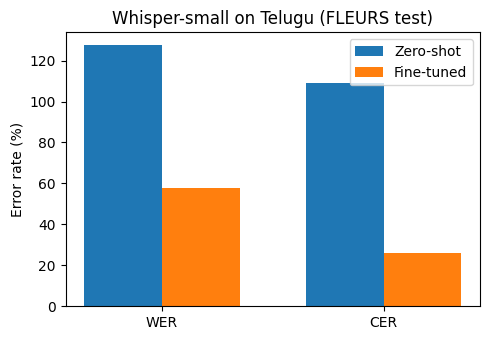

In [10]:
model.config.use_cache = True
ft_preds = transcribe(model, test_ds)
ft_scores = score(refs, ft_preds)
print("Baseline  :", base_scores)
print("Fine-tuned:", ft_scores)

results = {"model": MODEL_ID, "dataset": f"google/fleurs {FLEURS_CFG}",
           "n_train": len(train_ds), "n_test": len(test_ds), "max_steps": MAX_STEPS,
           "baseline": base_scores, "finetuned": ft_scores}
json.dump(results, open("results.json", "w"), indent=2)

fig, ax = plt.subplots(figsize=(5, 3.5))
x = np.arange(2); w = 0.35
ax.bar(x - w/2, [base_scores["WER"], base_scores["CER"]], w, label="Zero-shot")
ax.bar(x + w/2, [ft_scores["WER"], ft_scores["CER"]], w, label="Fine-tuned")
ax.set_xticks(x); ax.set_xticklabels(["WER", "CER"]); ax.set_ylabel("Error rate (%)")
ax.set_title("Whisper-small on Telugu (FLEURS test)"); ax.legend()
plt.tight_layout(); plt.savefig("wer_comparison.png", dpi=150); plt.show()

In [11]:
for i in range(5):
    print(f"--- sample {i} ---")
    print("REF :", refs[i])
    print("BASE:", base_preds[i])
    print("FT  :", ft_preds[i])

--- sample 0 ---
REF : ప్రతీ జనరేషన్తో రెండు సమూహాల మధ్య వేరుపరచడం ఇంకా తిరిగి కలపడం అనేది వైవిధ్యాన్నిముందుకు వెనుకకు మార్చుతుంది
BASE: प्रती ज़न्रेशन तो रव्द समूहाल मज्या वेर परचच़दम यह त्रीगी कलपडवा वेविद्याने मुझ्दूक वेनुका कु मार्च्चूत।
FT  : ప్రతి జన్రేషన్తో రెండు సమూహాల మధ్య వేరుపరచడం ఇంకా తిరిగి కలపడం అనేది వేవిధ్యాన్ని ముందుకు వెనుకకు మార్చుతుంది
--- sample 1 ---
REF : అదే రోజు సుమారు 1200 జిఎమ్ టి వద్ద ప్రమాదం జరిగిన స్థలం నుంచి వాహనాన్నే తీసుకెళ్లారు
BASE: अदे रोजो सुमार पन्निद वंदलों जीम्टी वद्द प्रमादम जरीएन स्तलम न वाहान न थीस किल लेरू
FT  : అదే రోజు సుమారు 1200 gmt వద్ద ప్రమాదం జరిగిన స్థలం నుంచి వాహనాన్నే తీసుకెళ్లరు
--- sample 2 ---
REF : వాటికన్ సిటీ జనాభా సుమారు 800 ఇది ప్రపంచంలో అతి చిన్న స్వతంత్ర దేశం ఇంకా అతి తక్కువ జనాభా కలిగిన దేశం
BASE: ಸಾರಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿಲಿ�
FT  : వాటికన్ సిటీ జనాపాసు 800 మనిని దీ ప్రభంటు నేతి చిన్న స్వతంత దేశింగ్ కొలిగినా తక్తువ జనాపాకులిగా దేశం
--- sam

## 6. Save (optional)
Run the cell below to download `results.json` and `wer_comparison.png`, then add them to your GitHub repo.

In [12]:
from google.colab import files
files.download("results.json"); files.download("wer_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>